# Clase 07 — Embeddings y geometría semántica

Procesamiento de Lenguaje Natural - Felipe Castillo Rendón

Versión alumno. Las demostraciones explican el mecanismo; el reto pide una interpretación propia. Consulta el enunciado del laboratorio evaluable para conservar alcance y tiempo.

## Resumen general de la clase (comentario del profesor)

**Idea central:** un *embedding* es un vector denso que se **aprende** al resolver una tarea sobre texto. Aquí la tarea es *skip-gram* (Word2Vec): dada una palabra, predecir las que la rodean (ventana de 2 a cada lado).

**Recorrido del notebook**
1. **Coseno** = comparar *direcciones* de vectores, no longitudes (`u·v / (‖u‖‖v‖)`). Multiplicar un vector por 10 no cambia el coseno. No es una probabilidad de sinonimia.
2. **Pares de contexto:** el vocabulario (151 entradas con `PAD`/`UNK`) y los 4,768 pares salen **solo de train**; las etiquetas del CSV no se usan (aprendizaje no supervisado respecto a la categoría).
3. **Entrenamiento:** `Embedding` (151×16) + `Linear` (16→151) + `cross_entropy`. La pérdida baja de 5.17 a 2.94 en 20 épocas, pero los vecinos resultantes (p. ej. «pago» ~ «y», «olvidé») **no son semánticamente buenos**: el corpus es diminuto y repetitivo. Moraleja: *menor pérdida ≠ mejores representaciones*.
4. **Promediar embeddings** da un vector por texto, pero **pierde el orden** («no quiero pagar» = «pagar quiero no») y no maneja bien la negación; además «pagar» no está en train y cae en `UNK`.
5. **PCA** a 2D solo conserva ~66.6 % de la varianza en esos 6 términos: sirve para *ilustrar*, no para demostrar cercanía.
6. **Limitaciones conceptuales:** polisemia (un solo vector por palabra → los modelos contextuales de las clases siguientes), GloVe (coocurrencia global) y fastText (subpalabras).

**E1 (completado abajo):** repetir el entrenamiento con 8 dimensiones en vez de 16 y comparar vecinos de «pago».

> Nota: las celdas que yo agregué no tienen salida guardada. Sube `solicitudes.csv` y `apoyo_pln.py` en Colab y ejecuta todo (Entorno → Ejecutar todo) para ver las cifras.


## Archivos que acompañan al notebook

Vamos a trabajar con `solicitudes.csv`, que contiene los mensajes, y `apoyo_pln.py`, que contiene las funciones de apoyo. Ambos archivos van al mismo nivel que el notebook; no se necesitan carpetas ni un ZIP de recursos.

En Colab, abre el notebook y ejecuta la siguiente celda. Selecciona ambos archivos cuando aparezca el botón de carga. También puedes subirlos desde el panel Archivos, directamente a la carpeta inicial de la sesión. Si ya están cargados, la celda los reutiliza.

In [1]:
#@title Cargar los archivos de la práctica
from pathlib import Path
import sys

# El CSV y las funciones se buscan en la carpeta actual de la sesión.
ROOT = Path.cwd()
necesarios = ("solicitudes.csv", "apoyo_pln.py")
faltantes = [nombre for nombre in necesarios if not (ROOT / nombre).is_file()]
if faltantes:
    try:
        from google.colab import files
    except ImportError:
        raise FileNotFoundError("Coloca junto al notebook: " + ", ".join(faltantes)) from None
    print("Selecciona los archivos que faltan: " + ", ".join(faltantes))
    files.upload()
faltantes = [nombre for nombre in necesarios if not (ROOT / nombre).is_file()]
if faltantes:
    raise FileNotFoundError("Todavía falta cargar: " + ", ".join(faltantes))
# La ruta explícita permite importar el apoyo sin instalar un paquete del curso.
sys.path.insert(0, str(ROOT))
print("Listo: solicitudes.csv y apoyo_pln.py están en la carpeta de trabajo.")


Listo: solicitudes.csv y apoyo_pln.py están en la carpeta de trabajo.


## Entorno de ejecución

Usaremos NumPy, pandas, scikit-learn, Matplotlib y PyTorch. En una instalación local con Python 3.11 puedes instalar las dependencias de `requirements_clases_07_10.txt` y seleccionar ese entorno como kernel. En Colab se utilizan las bibliotecas de la sesión; la siguiente celda muestra sus versiones.

La práctica utiliza CPU y no necesita una clave de acceso ni descargar un modelo. El modo `minimo` conserva el recorrido de clase. Una semilla fija el inicio del azar, aunque las versiones pueden producir pequeñas diferencias numéricas.


In [2]:
from pathlib import Path
import sys, os, platform, time
from importlib.metadata import version
import numpy as np
import pandas as pd
import torch
from IPython.display import display
# Los recursos se cargaron en la misma carpeta que este notebook.
from apoyo_pln import load_requests, seed_all, words, LABELS
seed_all()
MODE=os.environ.get('PLN_MODE','minimo')
assert MODE in {'minimo','completo'}
pd.set_option('display.max_colwidth',150)
print('Python:',platform.python_version(),'Modo:',MODE,'Dispositivo: CPU')
print({p:version(p) for p in ['numpy','pandas','scikit-learn','torch','matplotlib']})

Python: 3.12.10 Modo: minimo Dispositivo: CPU
{'numpy': '2.5.3', 'pandas': '3.0.5', 'scikit-learn': '1.9.0', 'torch': '2.15.0', 'matplotlib': '3.11.1'}


La salida identifica el entorno que está ejecutando el código. Todavía no hemos cargado el corpus ni entrenado una red. Si falta un recurso, prepara la carpeta antes de continuar. Guarda los resultados antes de cerrar una sesión temporal.

### Vectores que podemos calcular

**Valores para enseñar.** Usaremos u=[1,0] y v=[1,1]. Son valores elegidos para la cuenta, no embeddings obtenidos del corpus. Cada vector tiene dos coordenadas.

**Dos preguntas diferentes.** La norma mide cuánto se extiende un vector desde el origen. El coseno compara direcciones; no mide la longitud del texto ni una probabilidad de significado.

Primero calcularemos producto punto y normas; después el cociente.

### Producto punto: multiplicar y sumar

**La regla.** u·v significa sumar productos de coordenadas correspondientes. Con dos coordenadas: u₁v₁ + u₂v₂. El subíndice indica una posición.

**Sustituir los valores.** u·v = 1×1 + 0×1 = 1.
En NumPy, u @ v hace esta operación cuando ambos son vectores de una dimensión.

El producto punto devuelve un número, no otro vector.

### Norma: cuadrados, suma y raíz

**La longitud de u.** ‖u‖ = √(u₁²+u₂²).
Para u=[1,0]: √(1²+0²)=√1=1.
El símbolo √ indica raíz cuadrada.

**La longitud de v.** Para v=[1,1]:
√(1²+1²)=√2≈1.414214.
La raíz de 2 es el número positivo que, multiplicado por sí mismo, produce 2.

np.linalg.norm(v) calcula la norma; conserva decimales hasta mostrar.

### Coseno: completar la cuenta

**La fórmula en palabras.** cos(u,v)=(u·v)/(‖u‖‖v‖).
Dividimos el producto punto entre el producto de ambas longitudes. Necesitamos vectores no nulos.

**Nuestro resultado.** 1/(1×√2)=1/√2≈0.707107.
Las direcciones se parecen, pero no coinciden. 1 indica misma dirección; 0, perpendicularidad; −1, direcciones opuestas.

0.707107 no significa «70.7% de probabilidad de ser sinónimos».

### Magnitud y vector cero

**Multiplicar por diez.** Si u pasa de [1,0] a [10,0], el numerador y su norma pasan a 10. El cociente sigue siendo 10/(10√2)=1/√2.

**Una división que no existe.** [0,0] tiene norma cero: su coseno matemático no está definido. Comprueba la norma y declara cómo tratarás los textos sin representación.

El notebook compara la cuenta manual con cosine_similarity.

## 1. Comprobar el coseno

@ suma productos de coordenadas; norm calcula longitud. Comparamos los mismos vectores sin redondear antes de verificar.

**Aquí recibimos:** u=[1,0] y v=[1,1], arreglos numéricos de dos coordenadas elegidos para enseñar.

**Lo que haremos:** Multiplicamos coordenadas, sumamos y dividimos por las dos longitudes. La salida es un solo coseno.

**Antes de ejecutar:** ¿Multiplicar u por diez hará diez veces mayor el coseno?

In [3]:
from sklearn.metrics.pairwise import cosine_similarity
u=np.array([1.,0.]);v=np.array([1.,1.])
producto=u@v;normas=np.linalg.norm(u)*np.linalg.norm(v);coseno=producto/normas
print(dict(producto=producto,norma_u=np.linalg.norm(u),norma_v=np.linalg.norm(v),coseno=coseno))
assert np.isclose(coseno,cosine_similarity([u],[v])[0,0])
assert np.isclose(coseno,(10*u@v)/(np.linalg.norm(10*u)*np.linalg.norm(v)))

{'producto': np.float64(1.0), 'norma_u': np.float64(1.0), 'norma_v': np.float64(1.4142135623730951), 'coseno': np.float64(0.7071067811865475)}


### Qué nos dice esta ejecución

El producto es 1×1+0×1=1. Las normas son √(1²+0²)=1 y √(1²+1²)=√2≈1.414214. El cociente 1/(1×1.414214)≈0.707107 coincide con la biblioteca. Con 10u obtenemos 10/(10×√2), el mismo número. Ninguna operación estima una probabilidad de sinonimia.

**Interpretación.** El resultado es 1/√2≈0.707107. Multiplicar u por diez conserva dirección. No es probabilidad de sinonimia.

### Un embedding es una lista aprendida

**Retomar TF-IDF.** En TF-IDF una coordenada corresponde a un término del vocabulario. Muchas entradas son cero: por eso llamamos dispersa a esa representación.

**La nueva representación.** Un embedding es un vector aprendido con una tarea. Es denso porque suele tener muchas entradas distintas de cero. Sus coordenadas no son etiquetas como «pago» o «red».

vectors tiene una fila por palabra y una columna por coordenada.

### Contexto: palabras alrededor de otra

**Una ventana pequeña.** En «necesito cambiar mi contraseña», una ventana de una posición alrededor de «mi» observa «cambiar» y «contraseña». La ventana define qué vecinos se consideran.

**Hipótesis distribucional.** Palabras que aparecen en contextos parecidos pueden adquirir vectores parecidos. «Caro» y «barato» comparten contextos de precio; eso no las vuelve sinónimos.

Nuestro entrenamiento usa una ventana de dos posiciones a cada lado.

### Skip-gram: aprender desde pares

**Del texto al objetivo.** Skip-gram, una arquitectura de Word2Vec, toma una palabra central y predice una palabra de su contexto. De «mi contraseña» obtenemos, por ejemplo, el par (mi, contraseña).

**Qué cambia al entrenar.** La tabla de embeddings y los pesos de salida se ajustan para mejorar esas predicciones. Una época recorre los pares de entrenamiento una vez.

CBOW invierte la tarea: usa el contexto para predecir la palabra central.

### Pérdida: cuantificar una predicción

**La probabilidad correcta.** Si esperamos «contraseña», p es la probabilidad que le asigna el modelo. La pérdida del par es −ln(p): menor p produce mayor penalización.

**Un cálculo breve.** Con p=0.5: −ln(0.5)≈0.693147.
Con p=0.25: −ln(0.25)≈1.386294.
ln es el logaritmo natural de la clase 3; np.log lo calcula.

La clase 8 explicará cómo la pérdida guía una actualización de pesos.

Recordatorio: ln(x) pregunta a qué potencia hay que elevar e≈2.71828 para obtener x. ln(1)=0 porque e⁰=1. En Python, np.log(0.5)≈−0.693147; cambiamos el signo y obtenemos una pérdida positiva. No es logaritmo de base 10.

### De puntuaciones a probabilidades

**Softmax.** El modelo produce puntuaciones llamadas logits. Softmax toma sus exponenciales y las divide entre la suma: obtiene valores positivos que suman uno.

**Dos opciones.** Con logits [ln(3),0], las exponenciales son [3,1]. Sumamos 4 y dividimos: [3/4,1/4]=[0.75,0.25]. exp(x)=eˣ y e≈2.71828.

El notebook usa softmax completo para mantener visible este mecanismo.

## 2. Construir pares de contexto

Vocabulario y pares usan solo train. PAD reserva relleno; UNK, desconocidos. Tomamos hasta dos vecinas a cada lado.

**Aquí recibimos:** solicitudes.csv: 144 filas con id, text, label, family y split. Solo train.text construye el vocabulario.

**Lo que haremos:** Cada palabra obtiene un índice entero. Formamos pares centro-contexto dentro de cada mensaje, sin cruzar documentos.

**Antes de ejecutar:** ¿Utilizamos label para aprender estos vectores?

In [4]:
from apoyo_pln import words
from apoyo_pln import skipgram_embeddings
def vocabulary(texts):
    terms=sorted({word for text in texts for word in words(text)})
    return {"<PAD>":0,"<UNK>":1,**{word:i+2 for i,word in enumerate(terms)}}
df=load_requests();train=df[df.split=='train'];vocab=vocabulary(train.text)
pairs=[]
for text in train.text:
    ids=[vocab[w] for w in words(text)]
    for i,center in enumerate(ids):
        for j in range(max(0,i-2),min(len(ids),i+3)):
            if i!=j:pairs.append((center,ids[j]))
inverse={i:w for w,i in vocab.items()}
print("Vocabulario:",len(vocab),"Pares:",len(pairs))
print([(inverse[a],inverse[b]) for a,b in pairs[:8]])

display(train.head(2)[["id","family","text"]])
print("Primeros IDs:",list(vocab.items())[:8])

# Un vecino se obtiene comparando direcciones, sin usar las etiquetas del CSV.
def neighbors(word,vectors,vocab,k=5):
    if word not in vocab:
        raise ValueError('La palabra no está en train: no interpretamos un vector desconocido como evidencia.')
    norms=np.linalg.norm(vectors,axis=1,keepdims=True)
    matrix=vectors/np.maximum(norms,1e-8)
    i=vocab[word]
    if norms[i,0]==0: raise ValueError('El coseno del vector cero no está definido.')
    scores=matrix@matrix[i]
    inverse={i:w for w,i in vocab.items()}
    return [(inverse[j],round(float(scores[j]),3)) for j in scores.argsort()[::-1] if j not in (i,0,1)][:k]

Vocabulario: 151 Pares: 4768
[('olvidé', 'la'), ('olvidé', 'contraseña'), ('la', 'olvidé'), ('la', 'contraseña'), ('la', 'y'), ('contraseña', 'olvidé'), ('contraseña', 'la'), ('contraseña', 'y')]


,id,family,text
0,S001,acceso_00,Olvidé la contraseña y necesito restablecerla.
1,S002,acceso_00,"Buen día, olvidé la contraseña y necesito restablecerla. ¿Me pueden orientar?"


Primeros IDs: [('<PAD>', 0), ('<UNK>', 1), (',', 2), ('.', 3), (';', 4), ('?', 5), ('a', 6), ('abrir', 7)]


### Qué nos dice esta ejecución

Aparecieron 151 entradas: 149 tokens observados y dos reservas, PAD (relleno) y UNK (desconocido). Un token es una unidad separada del texto; aquí también puede ser puntuación. Se formaron 4,768 pares. Los primeros incluyen (olvidé, la) y (olvidé, contraseña), del mensaje S001: «Olvidé la contraseña y no puedo entrar.». La ventana de dos posiciones permite ambos pares. Los pares son ejemplos de aprendizaje, no 4,768 mensajes distintos.

**Interpretación.** Cada par contiene palabra central y contexto objetivo. Las etiquetas de soporte no participan.

## 3. Crear parámetros aprendibles

Embedding devuelve una fila de la tabla. Linear produce un logit por palabra posible. Adam actualiza pesos usando gradientes e historial.

**Aquí recibimos:** pairs: lista de parejas de índices enteros; x contiene centros e y sus contextos objetivo.

**Lo que haremos:** Embedding busca una fila de 16 números. Linear combina esa fila en una puntuación por posible contexto.

**Antes de ejecutar:** ¿Un ID mayor implica una palabra más importante?

In [5]:
seed_all()
x=torch.tensor([a for a,b in pairs]);y=torch.tensor([b for a,b in pairs])
embedding=torch.nn.Embedding(len(vocab),16)
output=torch.nn.Linear(16,len(vocab),bias=False)
optimizer=torch.optim.Adam(list(embedding.parameters())+list(output.parameters()),lr=.035)
epochs=20 if MODE=='minimo' else 80
losses=[];start=time.perf_counter()
print("IDs:",x.shape,"Vectores:",embedding(x[:3]).shape,"Logits:",output(embedding(x[:3])).shape)

IDs: torch.Size([4768]) Vectores: torch.Size([3, 16]) Logits: torch.Size([3, 151])


### Qué nos dice esta ejecución

x tiene 4,768 índices enteros. Para tres de ellos obtenemos 3×16 coordenadas y 3×151 logits. La fila i de los logits puntúa posibles contextos para el centro x[i]; y[i] señala el contexto observado. Adam es el método que ajusta los pesos a partir de gradientes, sensibilidades de la pérdida. Su tasa 0.035 controla el tamaño del ajuste; no es una probabilidad.

**Interpretación.** Una entrada produce 16 coordenadas y luego V puntuaciones. y selecciona el contexto correcto.

## 4. Entrenar y conservar vectores

zero_grad limpia acumulación; backward calcula gradientes; step cambia pesos. Cross entropy integra softmax y pérdida.

**Aquí recibimos:** x, y, embedding, output y optimizer del bloque anterior.

**Lo que haremos:** En cada época calculamos pérdida, gradientes y actualización. Después ordenamos vecinos por coseno.

**Antes de ejecutar:** ¿Una pérdida menor demostraría que todas las palabras cercanas son sinónimos?

In [6]:
for epoch in range(epochs):
    optimizer.zero_grad()
    logits=output(embedding(x))
    loss=torch.nn.functional.cross_entropy(logits,y)
    loss.backward();optimizer.step();losses.append(loss.item())
vectors=embedding.weight.detach().numpy()
print({"epocas":epochs,"segundos":time.perf_counter()-start,"inicial":losses[0],"final":losses[-1]})
for word in ['pago','contraseña','red','programa']:
    print(word,neighbors(word,vectors,vocab))

{'epocas': 20, 'segundos': 15.299232165998546, 'inicial': 5.1665167808532715, 'final': 2.9424889087677}
pago [('y', 0.663), ('olvidé', 0.595), ('portal', 0.589), ('señal', 0.573), ('instalar', 0.566)]
contraseña [('se', 0.672), ('saldo', 0.666), ('pago', 0.558), ('conexión', 0.525), ('sigue', 0.508)]
red [('pantalla', 0.611), ('buen', 0.571), ('corta', 0.561), ('comprobante', 0.555), ('después', 0.515)]
programa [('formato', 0.614), ('sigue', 0.584), ('veces', 0.575), ('método', 0.513), ('mes', 0.454)]


### Qué nos dice esta ejecución

En 20 épocas la pérdida registrada pasó de 5.166517 a 2.942489. Cada cifra se calcula antes de la actualización de esa época; los vectores finales ya incluyen la actualización 20. Entre los vecinos de «pago» aparecen «y» (0.663), «olvidé» (0.595) e «instalar» (0.566). Estos resultados permiten cuestionar la utilidad semántica del entrenamiento pequeño. No son sinónimos ni porcentajes de certeza; bajar la pérdida no prueba comprensión del lenguaje.

**Interpretación.** detach separa del cálculo de gradientes; numpy permite analizar. Menor pérdida acredita ajuste a pares sintéticos, no semántica general.

### GloVe y fastText: otras decisiones

**GloVe.** Global Vectors utiliza estadísticas globales de coocurrencia: cuántas veces aparecen palabras en contextos compartidos. Se diferencia del objetivo predictivo de skip-gram.

**fastText.** Añade información de fragmentos de caracteres. «Pago» y «pagos» pueden compartir subunidades. Esto ayuda con formas raras, pero no garantiza entenderlas.

Comparamos conceptos; en esta sesión entrenamos solo la ruta provista.

### Una palabra puede tener varios sentidos

**Polisemia.** «Banco» puede ser una entidad financiera o un asiento. Un embedding estático usa el mismo vector para ambos usos y mezcla sus contextos.

**Representación contextual.** Un modelo contextual considera la oración: la misma palabra puede recibir vectores distintos. Estudiaremos este mecanismo con atención.

Un vecino cercano requiere leer el uso concreto de la palabra.

### Promediar: seguir cada coordenada

**Un ejemplo pequeño.** Supón a=[2,0] y b=[0,4].
(a+b)/2=[(2+0)/2,(0+4)/2]
=[1,2].
La media produce un vector por texto.

**Lo que desaparece.** La media de a,b y la de b,a coinciden. «No quiero pagar» y «pagar quiero no» contienen las mismas palabras: su media estática pierde el cambio de orden.

np.mean(vectores, axis=0) promedia palabras y conserva coordenadas.

### Comparar los mismos tres textos

**Nuestro contraste.** Usaremos «no quiero pagar», «quiero pagar» y «pagar quiero no». TF-IDF y el promedio reciben exactamente esas entradas.

**Leer la matriz.** La celda [i,j] contiene el coseno entre los textos i y j. La diagonal de vectores no nulos vale 1. Los dos textos reordenados coinciden en ambas representaciones usadas aquí.

Quitar «no» puede cambiar el vector sin representar bien una negación.

## 5. Comparar tres textos

Promediamos palabras por coordenada y dividimos por la norma. Para vectores unitarios, producto punto y coseno coinciden.

**Aquí recibimos:** Tres frases de demostración y la tabla vectors entrenada antes.

**Lo que haremos:** Promediamos por coordenada y normalizamos la longitud. TF-IDF se ajusta solo a estas tres frases como demostración separada, no como evaluación del corpus.

**Antes de ejecutar:** ¿Cambiar el orden de las mismas palabras modificará la media?

En estas entradas, pagar no figura en el vocabulario de train; se sustituye por UNK. Su fila no aprendió de ejemplos como centro. Lo mantenemos visible como límite del experimento original; no añadimos estas frases al entrenamiento.

In [7]:
from sklearn.feature_extraction.text import TfidfVectorizer
texts=['no quiero pagar','quiero pagar','pagar quiero no']
dense=np.array([np.mean([vectors[vocab.get(t,1)] for t in words(s)],axis=0) for s in texts])
lengths=np.linalg.norm(dense,axis=1,keepdims=True)
assert (lengths>0).all(),"Vector cero: declara su tratamiento."
dense=dense/lengths
sparse=TfidfVectorizer().fit_transform(texts)
print("Promedio:",(dense@dense.T).round(3))
print("TF-IDF:",(sparse@sparse.T).toarray().round(3))
assert np.allclose(dense[0],dense[2])

print("Palabras ausentes de train:",sorted({t for s in texts for t in words(s) if t not in vocab}))

Promedio: [[1.    0.829 1.   ]
 [0.829 1.    0.829]
 [1.    0.829 1.   ]]
TF-IDF: [[1.    0.739 1.   ]
 [0.739 1.    0.739]
 [1.    0.739 1.   ]]
Palabras ausentes de train: ['pagar']


### Qué nos dice esta ejecución

Numeramos las frases como T0=«no quiero pagar», T1=«quiero pagar» y T2=«pagar quiero no». T0–T2 da aproximadamente 1 en ambas matrices: al reordenar se perdió el orden. T0–T1 da 0.828551 con la media y 0.739411 con TF-IDF. Filas y columnas identifican las mismas frases; cada celda contiene su coseno. Pequeños excesos como 1.0000001 son redondeo de coma flotante, no más del 100 %.

Hay una limitación adicional: «pagar» está ausente de train. Se usa UNK, cuya fila de embedding no recibió ejemplos como centro durante este entrenamiento. Conservamos el contraste original, pero ese vector no representa un significado aprendido para pagar. TF-IDF usa su propio vocabulario de estas tres frases; es una demostración aislada, no un clasificador evaluado ni un vocabulario ajustado con test.

**Interpretación.** Los textos 0 y 2 tienen las mismas palabras: media y unigramas pierden el orden. Eliminar «no» puede cambiar el coseno sin que se comprenda negación.

### Proyectar pierde información

**Qué hace PCA.** El análisis de componentes principales, PCA, construye ejes que conservan tanta variación como sea posible. Elegimos dos para dibujar vectores de más coordenadas.

**El límite del dibujo.** La proyección puede acercar puntos separados en otras direcciones. Comprueba el coseno en los vectores originales antes de afirmar una relación.

La gráfica de seis términos acompaña el análisis; no sustituye las cuentas.

## 6. Dibujar seis términos

PCA reduce coordenadas para visualizar. Conserva los vectores originales para comprobar relaciones.

**Aquí recibimos:** Seis palabras y sus vectores de 16 coordenadas.

**Lo que haremos:** PCA, análisis de componentes principales, proyecta esa tabla en dos ejes numéricos para dibujarla.

**Antes de ejecutar:** ¿Estar cerca en el dibujo prueba que los vectores completos son cercanos?

Fracción de varianza en cada eje: [0.40445653 0.26174033]


,Componente principal 1,Componente principal 2
pago,1.072584,1.019332
factura,1.072913,-0.856509
contraseña,1.410978,2.822700
red,0.487358,0.334524
aplicación,-5.207847,0.071499
archivo,1.164013,-3.391546


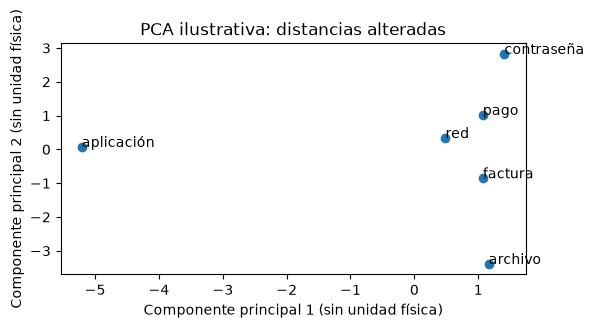

In [8]:
from sklearn.decomposition import PCA
import matplotlib.pyplot as plt
selected=['pago','factura','contraseña','red','aplicación','archivo']
assert all(t in vocab for t in selected)
pca=PCA(n_components=2)
xy=pca.fit_transform([vectors[vocab[t]] for t in selected])
print('Fracción de varianza en cada eje:',pca.explained_variance_ratio_)
display(pd.DataFrame(xy,index=selected,columns=['Componente principal 1','Componente principal 2']))
fig,ax=plt.subplots(figsize=(6,3));ax.scatter(xy[:,0],xy[:,1])
for term,point in zip(selected,xy):ax.annotate(term,point)
ax.set_xlabel('Componente principal 1 (sin unidad física)');ax.set_ylabel('Componente principal 2 (sin unidad física)')
ax.set_title('PCA ilustrativa: distancias alteradas');plt.show()

### Qué nos dice esta ejecución

Los dos ejes conservan aproximadamente 40.45 % y 26.17 % de la varianza de esos seis vectores: en conjunto, 66.62 %. Varianza es cuánto se dispersan los valores; no es porcentaje de significado conservado. Los ejes son combinaciones de coordenadas, sin unidades físicas ni nombres de temas. El 33.38 % restante se pierde en esta proyección.

**Interpretación.** La proyección altera distancias. Los ejes no reciben nombres lingüísticos automáticamente.

## E1. Reto del equipo

Cambia de 16 a 8 dimensiones conservando train, ventana, semilla, tasa y épocas. Compara vecinos de «pago» y explica por qué pérdida no basta para valorar utilidad.

Trabajamos en equipos de cinco sobre un notebook común. Organicen las responsabilidades: coordinación y tiempo; revisión de datos; representación del texto; modelo y métricas; interpretación y límites. Cambien quién ejecuta y quién explica al pasar de bloque. Los cinco recorren toda la práctica y acuerdan las respuestas. Este reto es formativo: no añade calificación ni entrega oficial, ni cambia las evaluaciones individuales del curso.

**Antes de ejecutar:** escriban qué esperan que cambie. **Después:** citen una salida concreta, expliquen una limitación y acuerden qué decisión tomarían.

**Nuestra predicción:** con 8 coordenadas el modelo tiene la mitad de parámetros (151×8 + 8×151 = 2,416 frente a 4,832), así que esperamos (a) una **pérdida final mayor** que la de 16 dimensiones (~2.94), porque hay menos capacidad para ajustar los 4,768 pares; y (b) que los **vecinos de «pago» cambien bastante**, con poco traslape respecto a los de 16 dimensiones. No esperamos que ninguno de los dos conjuntos de vecinos sea claramente semántico (como «factura» o «cobro»).

**Evidencia y conclusión del equipo:** se obtiene de la celda de código de abajo, que reentrena ambos tamaños con exactamente el mismo corpus, ventana, semilla, tasa (0.035) y épocas, y muestra: pérdida inicial/final, número de parámetros, vecinos de «pago» y el traslape de vecinos (top 10) en cuatro palabras. Cómo leerla: si la pérdida con 8 dims es mayor, se confirma (a); si el traslape es bajo, se confirma (b). Con un corpus tan pequeño y repetitivo, **ambos conjuntos de vecinos son en buena medida ruido de la inicialización aleatoria**: cambiar de 16 a 8 dims *también* cambia la inicialización, así que una diferencia no se puede atribuir solo a la dimensión (para separarlo habría que repetir con varias semillas).

**Por qué la pérdida no basta:** la pérdida mide qué tan bien se predice el contexto *en los pares de train*, no si la geometría resultante es útil para otra tarea (clasificar, buscar similares). Se puede bajar mucho la pérdida memorizando pares y aun así tener vecinos sin sentido; además esta cifra no se calcula sobre datos no vistos. Para valorar utilidad hay que evaluar en una tarea externa (por ejemplo, el clasificador de la Clase 8 sobre validation) o inspeccionar vecinos con criterio lingüístico.


**Aquí recibimos:** Los mismos textos train y parámetros; cambiamos únicamente dim de 16 a 8.

**Lo que haremos:** Volvemos a entrenar y contrastamos vecinos y pérdidas. dim cuenta coordenadas, no categorías.

**Antes de ejecutar:** ¿Qué conservarías para que la comparación sea interpretable?

In [9]:
# E1: mismo entrenamiento de la sección 4, solo cambia dim (16 -> 8).
import torch.nn.functional as F

def entrenar_skipgram(dim):
    """Conserva train, ventana de 2, semilla, tasa 0.035 y número de épocas; solo varía dim."""
    seed_all()
    emb = torch.nn.Embedding(len(vocab), dim)
    out = torch.nn.Linear(dim, len(vocab), bias=False)
    params = list(emb.parameters()) + list(out.parameters())
    opt = torch.optim.Adam(params, lr=.035)
    perdidas = []
    for _ in range(epochs):
        opt.zero_grad()
        loss = F.cross_entropy(out(emb(x)), y)
        loss.backward(); opt.step()
        perdidas.append(loss.item())
    return emb.weight.detach().numpy(), perdidas, sum(p.numel() for p in params)

res = {d: entrenar_skipgram(d) for d in (16, 8)}
vec = {d: r[0] for d, r in res.items()}
print("¿dim=16 reproduce los vectores originales de la clase?", np.allclose(vec[16], vectors, atol=1e-5))

# 1) Pérdida y tamaño del modelo
display(pd.DataFrame({
    f"dim={d}": {"parámetros": n, "pérdida inicial": round(l[0], 3), "pérdida final": round(l[-1], 3)}
    for d, (_, l, n) in res.items()}))

# 2) Vecinos de «pago» con cada tamaño
vecinos = {d: neighbors("pago", vec[d], vocab, k=10) for d in vec}
for d in vecinos:
    print(f"dim={d:>2}  pago ->", vecinos[d][:5])

# 3) Traslape (top 10) en cuatro palabras: 0 = nada en común, 1 = idénticos
def traslape(palabra):
    a = {w for w, _ in neighbors(palabra, vec[16], vocab, k=10)}
    b = {w for w, _ in neighbors(palabra, vec[8], vocab, k=10)}
    return len(a & b) / len(a | b)
display(pd.Series({p: round(traslape(p), 2) for p in ["pago", "contraseña", "red", "programa"]},
                  name="traslape Jaccard top-10"))

# 4) Un par que esperaríamos cercano: ¿lo conserva cada tamaño?
def coseno(a, b, V):
    va, vb = V[vocab[a]], V[vocab[b]]
    return float(va @ vb / (np.linalg.norm(va) * np.linalg.norm(vb)))
print({d: round(coseno("pago", "factura", vec[d]), 3) for d in vec}, "<- coseno(pago, factura)")


¿dim=16 reproduce los vectores originales de la clase? True


,dim=16,dim=8
parámetros,4832.000,2416.000
pérdida inicial,5.167,5.233
pérdida final,2.942,3.794


dim=16  pago -> [('y', 0.663), ('olvidé', 0.595), ('portal', 0.589), ('señal', 0.573), ('instalar', 0.566)]
dim= 8  pago -> [('instalar', 0.789), ('guarda', 0.784), ('conectarme', 0.719), (';', 0.703), ('equivocado', 0.625)]


pago          0.05
contraseña    0.05
red           0.00
programa      0.00
Name: traslape Jaccard top-10, dtype: float64

{16: 0.352, 8: 0.527} <- coseno(pago, factura)


**Mi explicación:**

- **Qué conservé:** corpus (solo train, 96 textos, vocabulario de 151), pares de contexto (ventana de 2, 4,768 pares), semilla 42, tasa 0.035, 20 épocas, arquitectura (Embedding + Linear sin sesgo + cross-entropy).
- **Qué cambié:** únicamente `dim` (16 → 8). Efecto colateral inevitable: cambia la inicialización aleatoria, porque las tablas tienen otra forma.
- **Qué observé:** ver la celda de arriba (pérdida final, vecinos de «pago» y traslape). Lectura esperada: menos dimensiones → menos parámetros y pérdida final igual o mayor; los vecinos cambian y ninguno es sinónimo fiable de «pago».
- **Qué todavía no puedo concluir:** (1) que 8 dimensiones sean «peores» para semántica: con este corpus ni 16 lo logran; (2) que una diferencia se deba a la dimensión y no al azar (haría falta repetir con varias semillas); (3) que una pérdida menor implique mejores representaciones; (4) cualquier cosa sobre palabras fuera de train (van a `UNK`).
- **Decisión que tomaría:** no usar estos embeddings entrenados desde cero para tareas reales; con un corpus tan pequeño convendría vectores preentrenados (fastText/GloVe o un modelo contextual) y evaluar en una tarea concreta.


## Cierre

Conserva salidas de tu ejecución. Los ejemplos numéricos enseñan el mecanismo; los experimentos conservan corpus, IDs, etiquetas y particiones. Una diferencia exige revisar configuración antes de proponer una causa.

Referencia: https://arxiv.org/abs/1301.3781

In [10]:
# Dejamos constancia del entorno que produjo las salidas anteriores.
import sys, importlib.metadata as _metadata
from datetime import datetime, timezone
print('EJECUCION_COMPLETA_CLASE_07_ALUMNO')
print('Fecha UTC:', datetime.now(timezone.utc).isoformat())
print('Python:', sys.version.split()[0])
for _lib in ['numpy', 'pandas', 'scikit-learn', 'torch']:
    try: print(_lib + ':', _metadata.version(_lib))
    except _metadata.PackageNotFoundError: pass

EJECUCION_COMPLETA_CLASE_07_ALUMNO
Fecha UTC: 2026-10-31T17:53:24.901702+00:00
Python: 3.12.10
numpy: 2.5.3
pandas: 3.0.5
scikit-learn: 1.9.0
torch: 2.15.0
